# Quick start

*Tsviki Y. Hirsh, 25 October 2026*

frame_overlap works like nbragg, with the pulse pattern as one more ingredient.
Here: 2 cm of iron, four pulses per 50 ms period at 9 m (times optimised for
the Bragg-edge position), a projected 8 h measurement, and its fit.

In [1]:
import nbragg
import frame_overlap as fo

xs = nbragg.CrossSection(iron="Fe_sg229_Iron-alpha.ncmat")         # the sample, as in nbragg
pattern = fo.Pattern([0, 11.97e-3, 22.33e-3, 35.48e-3])             # pulse start times [s]
model = fo.TransmissionModel(xs, pattern=pattern, vary_basic=True, vary_strain=True)
model.params["thickness"].set(value=2.0)                            # cm
model

TransmissionModel(4 pulse(s) of 200 us per 50 ms at 9 m; free: thickness, strain)

The expected counts: each pulse produces its own spectrum (fills), and the
detector records their sum. The beam here is the SARAF-II projection of the
article: 5e6 n/cm²/s on 72 mm² with 4.5 % detection efficiency.

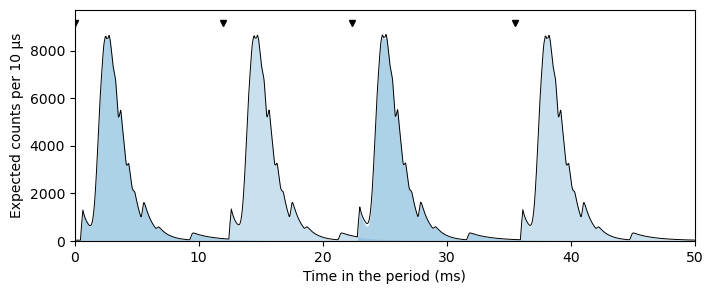

In [2]:
beam = dict(flux=5e6, area=0.72, efficiency=0.045)
model.plot(**beam);

A projected measurement of 8 h (Poisson counts with the 2.3-fold variance that
the event-mode camera records), and its Rietveld fit: the model is convolved
with the pulse pattern and fitted to the counts.

In [3]:
data = model.simulate(time=8 * 3600, count_variance=2.3, seed=1, **beam)
result = model.fit(data)
print(result.fit_report())

[[Rietveld fit]]
    converged after 11 evaluations
    deviance per bin = 2.410 (5000 bins); expected 2.3 for count_variance 2.3
[[Variables]]
    thickness         2.00097 +/- 0.000646   (truth 2)
    strain       -0.000112726 +/- 0.000127  = -112.7 +/- 127.3 microstrain   (truth 0)


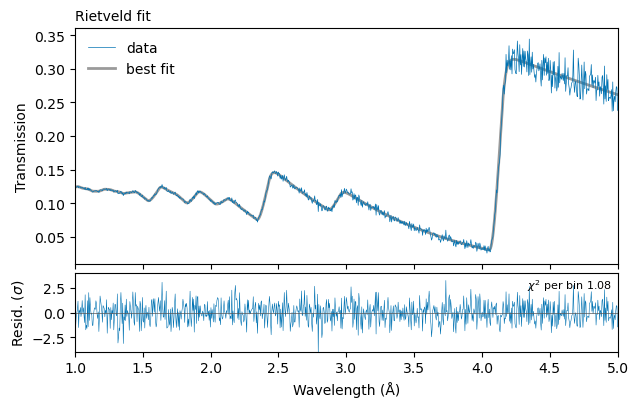

In [4]:
ax = result.plot()
ax.figure.savefig("../docs/fit_iron.png", dpi=150, bbox_inches="tight")

The plot shows the transmission recovered from the overlapped counts (the
counts of each bin divided between the pulses) with the fitted model, and the
residuals in units of their standard deviation.

For comparison, Wiener deconvolution as in frame-overlap Bragg-edge imaging
(FOBI): it spreads the noise of all pulses over the recovered spectrum and
loses most of the edge information.

[[Wiener deconvolution]]
    converged after 10 evaluations
    chi-square per bin = 2.245 (910 bins); expected 2.3 for count_variance 2.3
[[Variables]]
    thickness         2.00148 +/- 0.00331   (truth 2)
    strain        4.75834e-05 +/- 0.000734  = 47.6 +/- 734.4 microstrain   (truth 0)
    note: errors include the correlations created by the deconvolution (sandwich estimate)


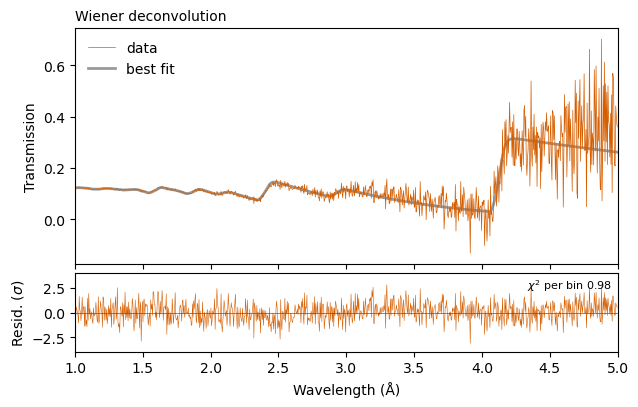

In [5]:
wiener = model.fit(data, method="wiener")
print(wiener.fit_report())
wiener.plot();

What this design can reach, from the Cramér–Rao bound of the Rietveld fit, and
how much shorter it is than one pulse per period:

In [6]:
print(model.precision(time=8 * 3600, count_variance=2.3, **beam)[["parameter", "sigma_display", "unit_display"]])
model.gain(**beam)

   parameter  sigma_display unit_display
0  thickness       6.445721           um
1     strain     127.258626  microstrain


{'thickness': 2.9662531046225853, 'strain': 3.894290779896838}